# Hotel Booking Cancellation Prediction — Exploratory Data Analysis

This notebook inspects the Hotel Booking Demand dataset before model development. It explains the data quality checks, explores the cancellation target and its relationship with booking attributes, and records decisions that affect later modeling.

The target is `is_canceled`. The intended use case is to estimate cancellation risk when a booking is created. For that reason, variables that reveal the outcome or are only known after booking creation must not be used as predictors. This notebook is exploratory; model-based feature importance and model selection will be covered in the modeling stage.

For technical definitions of all source columns, see the project [data dictionary](../docs/data_dictionary.md). The analysis and decisions about data quality and feature use are documented in the sections below.

## 1. Setup and data loading

We use pandas for tabular inspection and matplotlib/seaborn for plots. The path lookup supports running the notebook either from the project root or from the `notebooks/` directory. The raw file is kept unchanged; cleaning steps below create separate in-memory dataframes.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data/raw/hotel_bookings.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data/raw/hotel_bookings.csv"
assert DATA_PATH.exists(), f"Dataset not found at {DATA_PATH}. Run the notebook from the repository or notebooks directory."

bookings_raw = pd.read_csv(
    DATA_PATH,
    dtype={"agent": "str", "company": "str"},
)
print(f"Loaded {len(bookings_raw):,} rows and {bookings_raw.shape[1]} columns from data/raw/hotel_bookings.csv")

Loaded 119,390 rows and 32 columns from data/raw/hotel_bookings.csv


The dataset contains booking-level records from city and resort hotels. We first inspect the dimensions, variable names, sample records, and data types. This provides context for later checks and helps us catch unexpected changes to the source file.

In [2]:
display(bookings_raw.head())

data_overview = pd.DataFrame({
    "column": bookings_raw.columns,
    "dtype": bookings_raw.dtypes.astype(str).values,
    "missing_count": bookings_raw.isna().sum().values,
})
display(data_overview)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,column,dtype,missing_count
0,hotel,str,0
1,is_canceled,int64,0
2,lead_time,int64,0
3,arrival_date_year,int64,0
4,arrival_date_month,str,0
5,arrival_date_week_number,int64,0
6,arrival_date_day_of_month,int64,0
7,stays_in_weekend_nights,int64,0
8,stays_in_week_nights,int64,0
9,adults,int64,0


The sample rows show the raw booking-level structure and the mix of booking, guest, stay, and outcome fields. The structural table confirms the data types and identifies columns that contain missing values.

## 2. Target definition and class balance

`is_canceled` is the binary target: 1 indicates a canceled booking and 0 indicates a booking that was not canceled. Class balance matters because accuracy alone can be misleading when one outcome is more common. We report both counts and percentages and plot the distribution.

We quantify the target distribution to understand how many bookings were canceled and whether both classes have enough observations for model evaluation.

,bookings,share
is_canceled,,
0,75166,63.0%
1,44224,37.0%


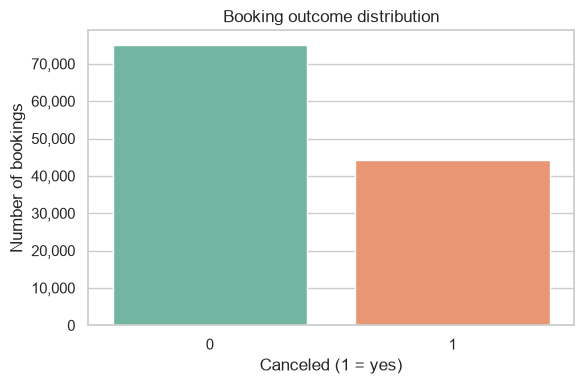

In [3]:
target_summary = (
    bookings_raw["is_canceled"]
    .value_counts(dropna=False)
    .rename_axis("is_canceled")
    .to_frame("bookings")
)
target_summary["share"] = target_summary["bookings"] / len(bookings_raw)
display(target_summary.style.format({"share": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=bookings_raw, x="is_canceled", hue="is_canceled", legend=False, palette="Set2", ax=ax)
ax.set(title="Booking outcome distribution", xlabel="Canceled (1 = yes)", ylabel="Number of bookings")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
plt.tight_layout()

The data are not perfectly balanced: the cancellation share is about 37% in the raw file. Both classes have substantial representation, but in later model evaluation we include class-sensitive metrics such as recall, precision, and ROC AUC rather than relying on accuracy alone.

## 3. Data quality: missing values, duplicates, and basic validity

Missing values may have different meanings across fields. In particular, the source data use absent `agent` and `company` values for many reservations; we do not automatically treat these records as erroneous. We inspect both missing-value counts and proportions.

We calculate missing-value counts and shares for every column so that we can distinguish isolated missing records from fields with systematic absence.

,missing_count,missing_share
company,112593,94.3%
agent,16340,13.7%
country,488,0.4%
children,4,0.0%


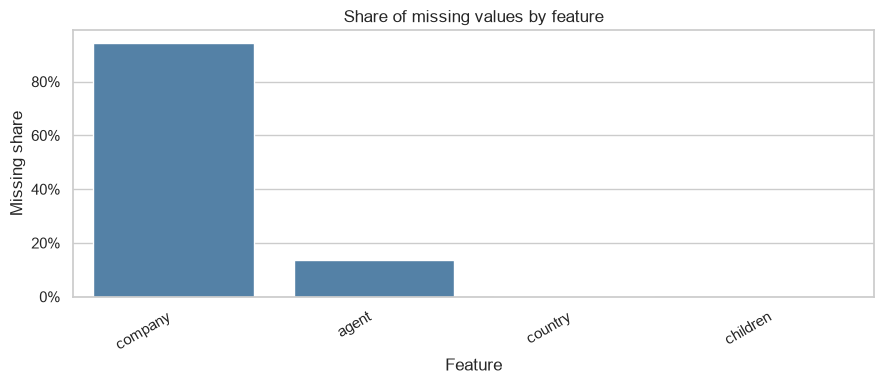

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": bookings_raw.isna().sum(),
    "missing_share": bookings_raw.isna().mean(),
}).query("missing_count > 0").sort_values("missing_share", ascending=False)
display(missing_summary.style.format({"missing_share": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=missing_summary.reset_index(names="feature"), x="feature", y="missing_share", color="steelblue", ax=ax)
ax.set(title="Share of missing values by feature", xlabel="Feature", ylabel="Missing share")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

There are four missing `children` values, so later preprocessing can impute those values or use an explicit missing-value strategy. The missing-value patterns are not homogeneous. `agent` and `company` contain not-applicable values according to the original dataset documentation, while `country` and `children` have a small number of absent values. The exact imputation and encoding strategy will be defined and evaluated in the modeling pipeline.

Exact duplicate rows deserve special attention. The dataset has no booking identifier, so we cannot determine whether identical rows are repeated source records or genuinely distinct bookings that happen to share every recorded attribute. We quantify duplicates and compare the target rate before and after removing exact duplicates; we keep the raw dataframe intact and defer the final modeling choice until validation design.

In [5]:
duplicate_mask = bookings_raw.duplicated(keep="first")
duplicate_count = int(duplicate_mask.sum())
unique_rows = bookings_raw.loc[~duplicate_mask].copy()

duplicate_summary = pd.DataFrame({
    "dataset": ["Raw rows", "Exact-duplicate rows removed", "Rows after exact deduplication"],
    "row_count": [len(bookings_raw), duplicate_count, len(unique_rows)],
})
display(duplicate_summary)
print(f"Raw cancellation rate: {bookings_raw['is_canceled'].mean():.3%}")
print(f"Cancellation rate after exact deduplication: {unique_rows['is_canceled'].mean():.3%}")
print(f"Exact duplicates as a share of raw rows: {duplicate_count / len(bookings_raw):.1%}")

,dataset,row_count
0,Raw rows,119390
1,Exact-duplicate rows removed,31994
2,Rows after exact deduplication,87396


Raw cancellation rate: 37.042%
Cancellation rate after exact deduplication: 27.490%
Exact duplicates as a share of raw rows: 26.8%


Exact duplicate rows are common in the dataset. Removing repeated copies would exclude 31,994 rows, equivalent to 26.8% of the raw data, and would change the cancellation rate from 37.0% to 27.5%. Because the dataset has no unique booking identifier, we cannot determine whether these rows are duplicated source records or distinct bookings with identical recorded attributes.

In [6]:
predictor_columns = [
    column for column in bookings_raw.columns
    if column != "is_canceled"
]

target_consistency = (
    bookings_raw
    .groupby(predictor_columns, dropna=False)["is_canceled"]
    .agg(
        target_values="nunique",
        row_count="size",
    )
)

conflicting_groups = target_consistency[
    target_consistency["target_values"] > 1
]

print(f"Groups with conflicting target values: {len(conflicting_groups)}")
print(f"Rows in conflicting groups: {conflicting_groups['row_count'].sum()}")

Groups with conflicting target values: 0
Rows in conflicting groups: 0


We found no cases where identical non-target values were associated with different target values. We retain the raw data during EDA and defer the final deduplication and validation policy to the modeling stage.

We check values that may signal data problems: zero-night stays, bookings with no adults, and negative or very large ADR (average daily rate). These checks do not automatically mean the records are invalid; they identify observations for contextual review. We validate the arrival date fields separately in the next section.

In [7]:
quality_checks = pd.Series({
    "zero_night_stays": ((bookings_raw["stays_in_weekend_nights"] + bookings_raw["stays_in_week_nights"]) == 0).sum(),
    "no_adults": (bookings_raw["adults"] == 0).sum(),
    "negative_adr": (bookings_raw["adr"] < 0).sum(),
    "adr_above_1000": (bookings_raw["adr"] > 1000).sum(),
})
display(quality_checks.rename("row_count").to_frame())

,row_count
zero_night_stays,715
no_adults,403
negative_adr,1
adr_above_1000,1


We review extreme values rather than remove them reflexively: unusual ADR values or guest counts may be data errors, but dropping them without evidence could also remove valid cases. `adr` includes negative and very large values, which we revisit before model fitting.

## 4. Booking and arrival-time patterns

Arrival dates are stored as separate year, month, and day fields. We create an arrival date for chronological summaries and visualizations. This derived value is useful for analysis, but any time-based train/validation split must be planned deliberately to avoid evaluating on a random mixture of past and future periods.

We convert the separate arrival year, month, and day columns into a single arrival date so that we can summarize cancellation patterns over time.

In [8]:
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
month_number = {month: number for number, month in enumerate(month_order, start=1)}
month_values = bookings_raw["arrival_date_month"].map(month_number)
bookings = bookings_raw.copy()
bookings["arrival_date"] = pd.to_datetime({
    "year": bookings["arrival_date_year"],
    "month": month_values,
    "day": bookings["arrival_date_day_of_month"],
}, errors="coerce")

print("Arrival date range:", bookings["arrival_date"].min(), "to", bookings["arrival_date"].max())
print("Rows with invalid/unparsed arrival date:", bookings["arrival_date"].isna().sum())
display(bookings["arrival_date"].dt.year.value_counts().sort_index().rename("bookings").to_frame())

Arrival date range: 2015-07-01 00:00:00 to 2017-08-31 00:00:00
Rows with invalid/unparsed arrival date: 0


,bookings
arrival_date,
2015,21996
2016,56707
2017,40687


The arrival date is now available for chronological summaries, and all rows have a valid parsed arrival date. We use this derived field in the following time-based analysis.

,bookings,cancellation_rate
arrival_date,,
2015,21996,37.0%
2016,56707,35.9%
2017,40687,38.7%


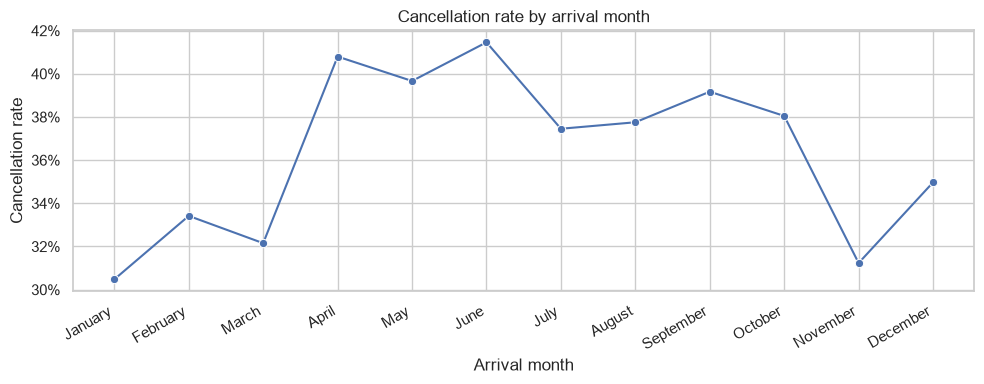

In [9]:
yearly_cancellation = bookings.groupby(bookings["arrival_date"].dt.year)["is_canceled"].agg(["size", "mean"])
yearly_cancellation = yearly_cancellation.rename(columns={"size": "bookings", "mean": "cancellation_rate"})
display(yearly_cancellation.style.format({"cancellation_rate": "{:.1%}"}))

monthly_cancellation = bookings.groupby(bookings["arrival_date"].dt.month)["is_canceled"].agg(["size", "mean"])
monthly_cancellation.index = [month_order[i - 1] for i in monthly_cancellation.index]

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(x=monthly_cancellation.index, y=monthly_cancellation["mean"], marker="o", ax=ax)
ax.set(title="Cancellation rate by arrival month", xlabel="Arrival month", ylabel="Cancellation rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

The yearly and monthly summaries show how the cancellation rate varies across the arrival period. We treat these patterns as descriptive signals and consider their temporal implications for validation.

Seasonality and year-to-year shifts may matter. This plot is descriptive, not evidence that the arrival month causes cancellation. It also shows why we will consider a time-aware split: a random split may overstate performance if future booking patterns differ from earlier ones.

## 5. Target relationships with selected features

We compare cancellation rates across `hotel`, `deposit_type`, and `market_segment`. We selected these features because they represent different dimensions of a booking: hotel type, payment policy, and commercial channel. They also have relatively low cardinality, which makes their group-level rates easy to inspect. These are unadjusted associations and do not isolate causal effects.

In [10]:
def cancellation_rate_table(frame, feature, min_count=0):
    table = frame.groupby(feature, dropna=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
    return table.loc[table["bookings"] >= min_count].sort_values("cancellation_rate", ascending=False)

display(cancellation_rate_table(bookings, "hotel").style.format({"cancellation_rate": "{:.1%}"}))
display(cancellation_rate_table(bookings, "deposit_type").style.format({"cancellation_rate": "{:.1%}"}))
display(cancellation_rate_table(bookings, "market_segment").style.format({"cancellation_rate": "{:.1%}"}))

,bookings,cancellation_rate
hotel,,
City Hotel,79330,41.7%
Resort Hotel,40060,27.8%


,bookings,cancellation_rate
deposit_type,,
Non Refund,14587,99.4%
No Deposit,104641,28.4%
Refundable,162,22.2%


,bookings,cancellation_rate
market_segment,,
Undefined,2,100.0%
Groups,19811,61.1%
Online TA,56477,36.7%
Offline TA/TO,24219,34.3%
Aviation,237,21.9%
Corporate,5295,18.7%
Direct,12606,15.3%
Complementary,743,13.1%


We visualize the cancellation rates for the selected categorical features side by side, making the differences easier to compare.

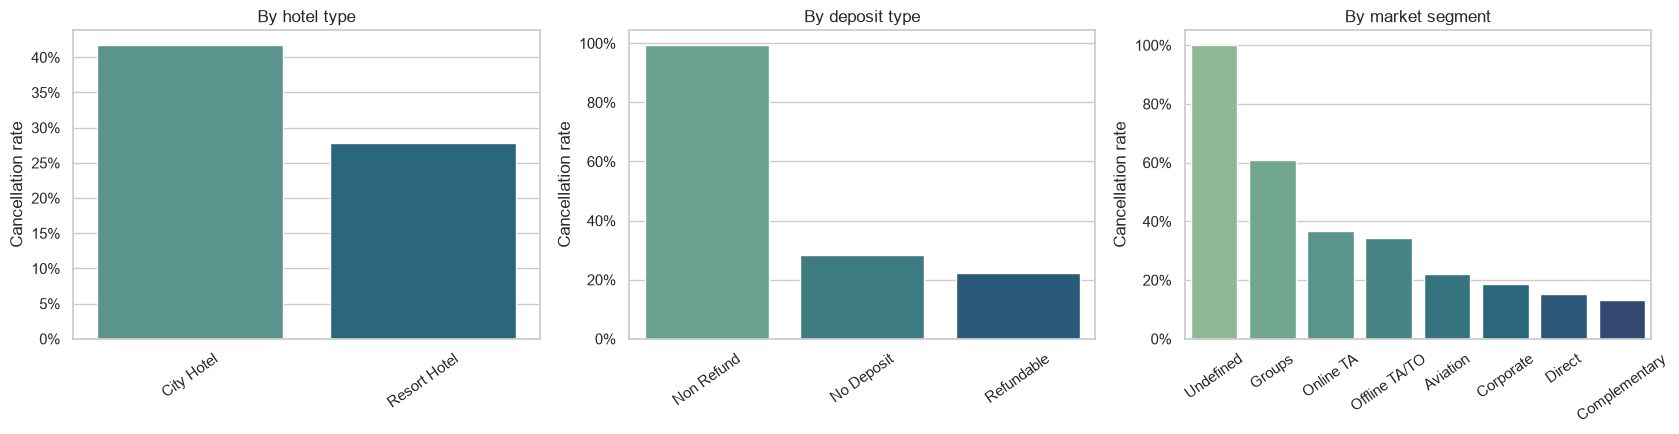

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, feature, title in zip(
    axes,
    ["hotel", "deposit_type", "market_segment"],
    ["By hotel type", "By deposit type", "By market segment"],
):
    rates = bookings.groupby(feature)["is_canceled"].mean().sort_values(ascending=False)
    sns.barplot(x=rates.index, y=rates.values, hue=rates.index, legend=False, palette="crest", ax=ax)
    ax.set(title=title, xlabel="", ylabel="Cancellation rate")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()

The plots show clear differences in cancellation rates across hotel type, deposit type, and market segment. We use these unadjusted comparisons to identify candidate signals for modeling, not to make causal claims.

In the raw data, City Hotel bookings have a higher cancellation rate than Resort Hotel bookings. Cancellation rates also differ across deposit types and market segments, but rare categories and business rules can influence these comparisons. The `Undefined` market-segment category has a 100% cancellation rate but only two bookings, so that estimate is not stable or representative. The `Non Refund` deposit category has a cancellation rate of about 99.4% across 14,587 bookings, making it a very strong dataset association that we should not interpret as a causal effect. We retain group sizes alongside rates and use validated models rather than interpret these raw rates as standalone effects.

## 6. Numeric feature distributions and cancellation rates

We first summarize numeric variables with counts, ranges, quartiles, and means. Several count-based variables are concentrated at zero, while `lead_time` and `adr` have wide ranges and potential outliers. We then compare selected distributions and medians across cancellation outcomes. For lead time, we create broad bins to make the relationship with cancellation risk easier to inspect; this binning is for visualization only.

The numeric summary gives us the descriptive baseline for the distribution plots and target comparisons below.

In [12]:
numeric_summary = bookings_raw.select_dtypes(include="number").describe().T
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


The summary confirms that several numeric variables are zero-inflated or strongly skewed. We use this information when interpreting the distributions and selecting robust preprocessing steps later.

,not_canceled_median,canceled_median
lead_time,45.0,113.0
adr,92.5,96.2
days_in_waiting_list,0.0,0.0
stays_in_weekend_nights,1.0,1.0
stays_in_week_nights,2.0,2.0
adults,2.0,2.0
children,0.0,0.0
babies,0.0,0.0
previous_cancellations,0.0,0.0
booking_changes,0.0,0.0


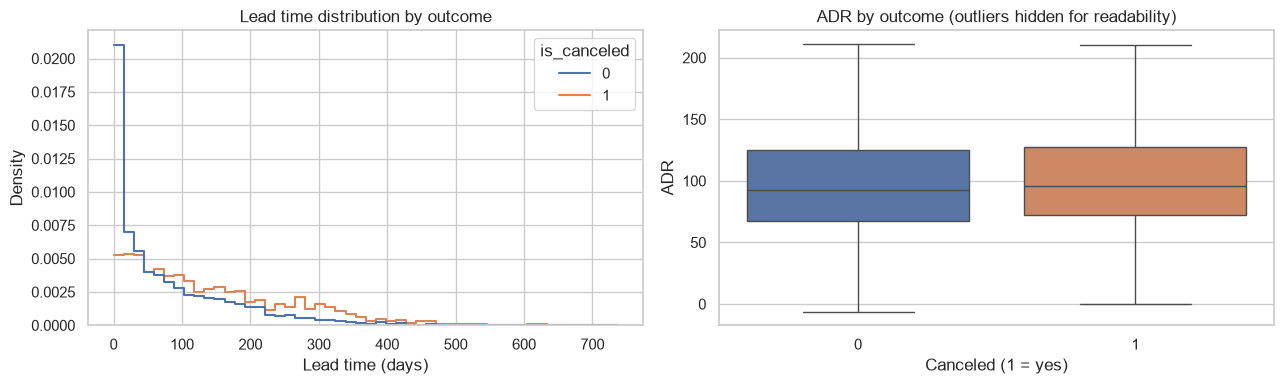

In [13]:
numeric_features = [
    "lead_time", "adr", "days_in_waiting_list", "stays_in_weekend_nights",
    "stays_in_week_nights", "adults", "children", "babies",
    "previous_cancellations", "booking_changes", "total_of_special_requests",
]
median_by_target = bookings.groupby("is_canceled")[numeric_features].median().T
median_by_target.columns = ["not_canceled_median", "canceled_median"]
display(median_by_target)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=bookings, x="lead_time", hue="is_canceled", bins=50, stat="density", common_norm=False,
             element="step", fill=False, ax=axes[0])
axes[0].set(title="Lead time distribution by outcome", xlabel="Lead time (days)")
sns.boxplot(data=bookings, x="is_canceled", y="adr", hue="is_canceled", legend=False, showfliers=False, ax=axes[1])
axes[1].set(title="ADR by outcome (outliers hidden for readability)", xlabel="Canceled (1 = yes)", ylabel="ADR")
plt.tight_layout()

The medians and outcome-specific distributions provide a more focused view of how the selected numeric variables differ between canceled and non-canceled bookings. The `lead_time` histogram uses `stat="density"`, so its y-axis shows normalized distribution shape rather than the number of bookings. With `common_norm=False`, each cancellation class is normalized separately, which makes their shapes comparable despite their different class sizes.

,bookings,cancellation_rate
lead_time_group,,
0–7,19746,9.6%
8–30,18960,27.9%
31–90,29553,37.7%
91–180,26439,44.7%
181–365,21544,55.5%
366+,3148,67.7%


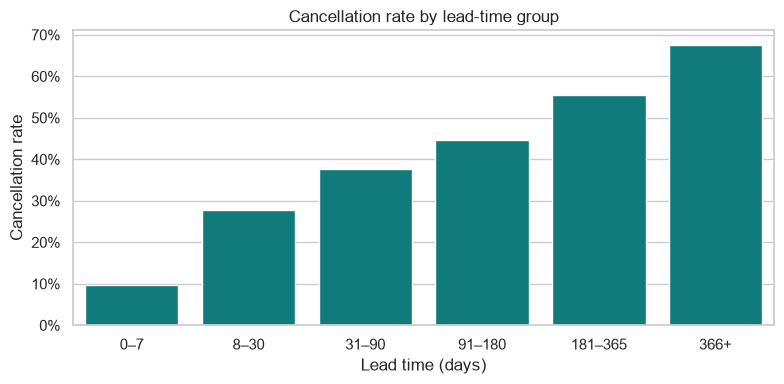

In [14]:
bookings["lead_time_group"] = pd.cut(
    bookings["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, np.inf],
    labels=["0–7", "8–30", "31–90", "91–180", "181–365", "366+"],
)
lead_time_rates = bookings.groupby("lead_time_group", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
display(lead_time_rates.style.format({"cancellation_rate": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=lead_time_rates.reset_index(), x="lead_time_group", y="cancellation_rate", color="darkcyan", ax=ax)
ax.set(title="Cancellation rate by lead-time group", xlabel="Lead time (days)", ylabel="Cancellation rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.tight_layout()

The lead-time groups make the relationship easier to read: cancellation rates vary across booking horizons, so lead time is a candidate predictive signal.

The raw median lead time is higher for canceled reservations than for non-canceled reservations, and the binned rates help show how risk varies across lead-time ranges. This pattern is a candidate signal for a model, but it may interact with hotel type, deposit policy, and booking channel.

## 7. Categorical feature cardinality and target association

High-cardinality fields require special handling in a model. We inspect the number of categories and show cancellation rates only for categories with enough observations. `country`, `agent`, and `company` have many levels; sparse category rates can be noisy, so we do not over-interpret them.

String columns require a different summary because their numeric statistics are not meaningful. We report the number of distinct values, the most frequent category, and the five most frequent values for each string column. This helps us identify low-cardinality categorical features as well as high-cardinality fields that may need special treatment.

In [15]:
categorical_features = bookings_raw.select_dtypes(include=["str"]).columns.tolist()

categorical_summary = pd.DataFrame({
    "column": categorical_features,
    "n_unique": [bookings_raw[column].nunique(dropna=False) for column in categorical_features],
    "most_frequent": [bookings_raw[column].value_counts(dropna=False).index[0] for column in categorical_features],
    "most_frequent_count": [bookings_raw[column].value_counts(dropna=False).iloc[0] for column in categorical_features],
    "top_5_values": [
        bookings_raw[column].value_counts(dropna=False).head(5).index.tolist()
        for column in categorical_features
    ],
})
display(categorical_summary)

,column,n_unique,most_frequent,most_frequent_count,top_5_values
0,hotel,2,City Hotel,79330,"[City Hotel, Resort Hotel]"
1,arrival_date_month,12,August,13877,"[August, July, May, October, April]"
2,meal,5,BB,92310,"[BB, HB, SC, Undefined, FB]"
3,country,178,PRT,48590,"[PRT, GBR, FRA, ESP, DEU]"
4,market_segment,8,Online TA,56477,"[Online TA, Offline TA/TO, Groups, Direct, Cor..."
5,distribution_channel,5,TA/TO,97870,"[TA/TO, Direct, Corporate, GDS, Undefined]"
6,reserved_room_type,10,A,85994,"[A, D, E, F, G]"
7,assigned_room_type,12,A,74053,"[A, D, E, F, G]"
8,deposit_type,3,No Deposit,104641,"[No Deposit, Non Refund, Refundable]"
9,agent,334,9,31961,"[9, nan, 240, 1, 14]"


The categorical summary shows which string columns have few categories and which have high cardinality.

In [16]:
cardinality = pd.DataFrame({
    "n_unique": bookings[categorical_features].nunique(dropna=False),
    "missing": bookings[categorical_features].isna().sum(),
}).sort_values("n_unique", ascending=False)
display(cardinality)

for feature in ["customer_type", "meal", "reserved_room_type", "distribution_channel"]:
    print(f"\nCancellation rates for {feature} (at least 100 bookings per category):")
    display(cancellation_rate_table(bookings, feature, min_count=100).style.format({"cancellation_rate": "{:.1%}"}))

,n_unique,missing
reservation_status_date,926,0
company,353,112593
agent,334,16340
country,178,488
arrival_date_month,12,0
assigned_room_type,12,0
reserved_room_type,10,0
market_segment,8,0
meal,5,0
distribution_channel,5,0



Cancellation rates for customer_type (at least 100 bookings per category):


,bookings,cancellation_rate
customer_type,,
Transient,89613,40.7%
Contract,4076,31.0%
Transient-Party,25124,25.4%
Group,577,10.2%



Cancellation rates for meal (at least 100 bookings per category):


,bookings,cancellation_rate
meal,,
FB,798,59.9%
BB,92310,37.4%
SC,10650,37.2%
HB,14463,34.5%
Undefined,1169,24.5%



Cancellation rates for reserved_room_type (at least 100 bookings per category):


,bookings,cancellation_rate
reserved_room_type,,
H,601,40.8%
A,85994,39.1%
G,2094,36.4%
C,932,33.0%
B,1118,32.9%
D,19201,31.8%
F,2897,30.4%
E,6535,29.3%



Cancellation rates for distribution_channel (at least 100 bookings per category):


,bookings,cancellation_rate
distribution_channel,,
TA/TO,97870,41.0%
Corporate,6677,22.1%
GDS,193,19.2%
Direct,14645,17.5%


The cardinality and category-level rates show that some categorical fields have sparse levels. We keep category counts visible and defer encoding choices to the modeling pipeline.

The assigned room type may be changed after the booking is created, and therefore deserves special scrutiny under a booking-time prediction definition. It can be useful in retrospective analysis while still being unavailable or leakage-prone at inference time. We keep the distinction between exploratory usefulness and deployable availability explicit.

## 8. Feature association analysis

We inspect numeric correlations and mutual information to identify potentially informative variables before modeling. These are exploratory measures, not causal effects and not a substitute for validated model-based feature importance.

We keep the raw dataframe for the first view and compare target correlations with the deduplicated dataframe as a sensitivity check. Correlation uses pairwise available values, so it does not require us to remove rows or permanently impute missing values. Mutual information requires complete numeric input, so we use temporary median imputation for numeric variables and a temporary `Missing` category for categorical variables. We do not scale the variables because scaling is not required for correlation or mutual information.

,raw,deduplicated
lead_time,0.293123,0.184806
total_of_special_requests,-0.234658,-0.120545
required_car_parking_spaces,-0.195498,-0.184206
booking_changes,-0.144381,-0.093644
previous_cancellations,0.110133,0.051468
is_repeated_guest,-0.084793,-0.089643
adults,0.060017,0.081816
previous_bookings_not_canceled,-0.057358,-0.052154
days_in_waiting_list,0.054186,0.004464
adr,0.047557,0.127986


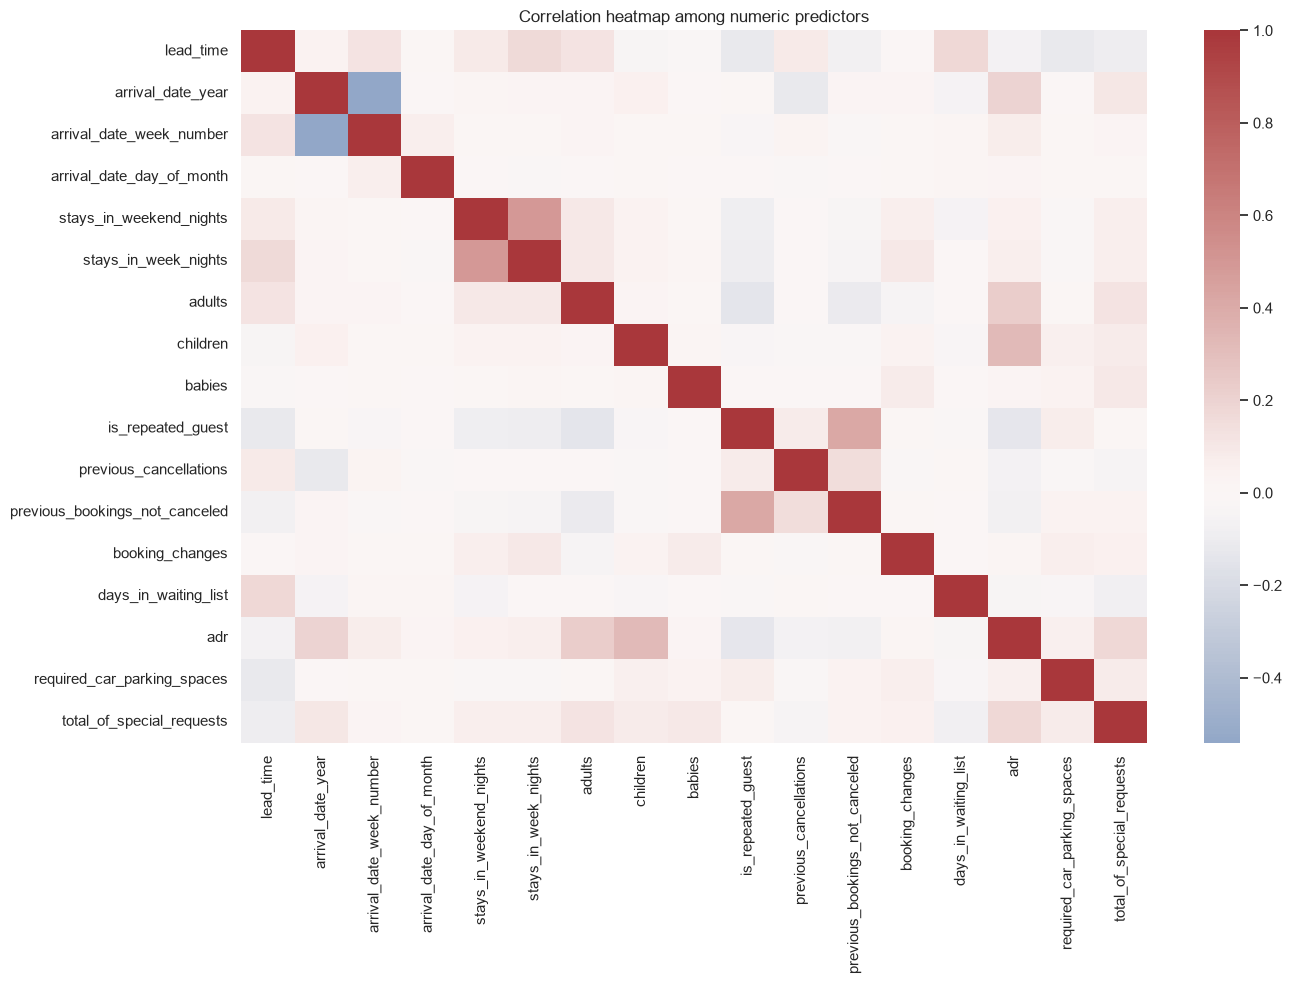

In [17]:
numeric_columns = bookings_raw.select_dtypes(include="number").columns.tolist()
numeric_predictors = [column for column in numeric_columns if column != "is_canceled"]

predictor_correlation_matrix = bookings_raw[numeric_predictors].corr()

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(predictor_correlation_matrix, cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation heatmap among numeric predictors")
plt.tight_layout()

target_correlation_raw = (
    bookings_raw[numeric_predictors + ["is_canceled"]]
    .corr()["is_canceled"]
    .drop("is_canceled")
)
target_correlation_deduplicated = (
    unique_rows[numeric_predictors + ["is_canceled"]]
    .corr()["is_canceled"]
    .drop("is_canceled")
)

correlation_comparison = pd.DataFrame({
    "raw": target_correlation_raw,
    "deduplicated": target_correlation_deduplicated,
})
correlation_comparison["absolute_raw"] = correlation_comparison["raw"].abs()
correlation_comparison = correlation_comparison.sort_values("absolute_raw", ascending=False).drop(columns="absolute_raw")
display(correlation_comparison)

The heatmap summarizes linear relationships among numeric predictors only; `is_canceled` is intentionally shown separately in the target-correlation table. That table shows how the strongest target associations change after exact deduplication. Differences between the raw and deduplicated columns indicate that repeated rows influence the descriptive association, which reinforces the need to make the final duplicate policy explicit during modeling.

In [18]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

association_excluded = {"is_canceled", "reservation_status", "reservation_status_date"}
y = bookings_raw["is_canceled"]

# Numeric variables: temporary median imputation is used only for this analysis.
mi_numeric_features = [column for column in numeric_predictors]
X_numeric_mi = bookings_raw[mi_numeric_features].copy()
X_numeric_mi = X_numeric_mi.fillna(X_numeric_mi.median())
mi_numeric_values = mutual_info_classif(
    X_numeric_mi,
    y,
    discrete_features=False,
    random_state=42,
)

mi_numeric = (
    pd.Series(mi_numeric_values, index=mi_numeric_features, name="mutual_information")
    .sort_values(ascending=False)
    .to_frame()
)

# String variables: missing values become an explicit temporary category.
mi_categorical_features = [
    column for column in bookings_raw.select_dtypes(include=["str"]).columns
    if column not in association_excluded
]
X_categorical_mi = bookings_raw[mi_categorical_features].fillna("Missing")
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_categorical_encoded = encoder.fit_transform(X_categorical_mi)
mi_categorical_values = mutual_info_classif(
    X_categorical_encoded,
    y,
    discrete_features=True,
    random_state=42,
)

mi_categorical = (
    pd.Series(mi_categorical_values, index=mi_categorical_features, name="mutual_information")
    .sort_values(ascending=False)
    .to_frame()
)

print("Top numeric features by mutual information:")
display(mi_numeric.head(10))
print("Top categorical features by mutual information:")
display(mi_categorical.head(10))

Top numeric features by mutual information:


,mutual_information
lead_time,0.080078
adr,0.077507
previous_cancellations,0.040393
total_of_special_requests,0.039312
required_car_parking_spaces,0.029531
booking_changes,0.018965
days_in_waiting_list,0.016696
adults,0.013014
stays_in_week_nights,0.012072
previous_bookings_not_canceled,0.007766


Top categorical features by mutual information:


,mutual_information
deposit_type,0.130952
agent,0.080440
country,0.067132
market_segment,0.036687
assigned_room_type,0.021782
distribution_channel,0.017106
company,0.012666
customer_type,0.009796
hotel,0.009541
reserved_room_type,0.002776


Mutual information can capture nonlinear dependence, so it complements the correlation analysis. We exclude the direct outcome fields (`reservation_status`, `reservation_status_date`) from this analysis because they leak the target. The values are useful for screening, but the final feature set still depends on timing, preprocessing, validation, and model performance.

## 9. Leakage review and excluded fields

The target describes a final booking outcome. Variables recorded after that outcome or during the stay can leak the answer. We exclude `reservation_status` and `reservation_status_date` because they directly describe the final reservation status and date. We also exclude `booking_changes` and `days_in_waiting_list` because their definitions explicitly depend on events after the booking is entered. This section records the fields excluded from the strict booking-time feature set; the data dictionary only defines what the columns mean.

In [19]:
import textwrap

leakage_review = pd.DataFrame([
    ("reservation_status", "Directly reveals the eventual outcome", "Exclude"),
    ("reservation_status_date", "Date associated with final reservation status", "Exclude"),
    ("booking_changes", "Counts changes through check-in or cancellation", "Exclude from strict booking-time model"),
    ("days_in_waiting_list", "Measures time until booking confirmation", "Exclude from strict booking-time model"),
])
leakage_review.columns = ["feature", "timing concern", "preliminary policy"]

leakage_review_display = leakage_review.copy()
for column in ["timing concern", "preliminary policy"]:
    leakage_review_display[column] = leakage_review_display[column].map(
        lambda text: textwrap.fill(text, width=45)
    )

display(
    leakage_review_display.style
    .set_properties(**{"white-space": "pre-wrap", "text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]},
        {"selector": "td", "props": [("vertical-align", "top")]},
    ])
)

DIRECT_LEAKAGE = ["reservation_status", "reservation_status_date"]
STRICT_TIMING_EXCLUDED = [
    "booking_changes",
    "days_in_waiting_list",
]
STRICT_MODEL_EXCLUDED = DIRECT_LEAKAGE + STRICT_TIMING_EXCLUDED
print("Direct leakage fields present:", [c for c in DIRECT_LEAKAGE if c in bookings_raw.columns])
print("Strict timing exclusions present:", [c for c in STRICT_TIMING_EXCLUDED if c in bookings_raw.columns])

,feature,timing concern,preliminary policy
0,reservation_status,Directly reveals the eventual outcome,Exclude
1,reservation_status_date,Date associated with final reservation status,Exclude
2,booking_changes,Counts changes through check-in or cancellation,Exclude from strict booking-time model
3,days_in_waiting_list,Measures time until booking confirmation,Exclude from strict booking-time model


Direct leakage fields present: ['reservation_status', 'reservation_status_date']
Strict timing exclusions present: ['booking_changes', 'days_in_waiting_list']


The table makes the timing concerns explicit for each potentially problematic field and gives us a preliminary policy for the strict booking-time model.

The table identifies the fields that directly reveal the outcome and the fields whose definitions depend on events after the booking is entered. These timing findings guide the feature decisions in the next stage.

## 10. EDA summary

This EDA establishes the target, the main data-quality issues, and the timing constraints for prediction.

In [20]:
eda_summary = {
    "raw_rows": len(bookings_raw),
    "columns": bookings_raw.shape[1],
    "cancellation_rate_raw": bookings_raw["is_canceled"].mean(),
    "exact_duplicate_rows": int(bookings_raw.duplicated().sum()),
    "missing_columns": missing_summary.index.tolist(),
    "arrival_date_start": bookings["arrival_date"].min(),
    "arrival_date_end": bookings["arrival_date"].max(),
    "direct_leakage_fields": DIRECT_LEAKAGE,
}
eda_summary

{'raw_rows': 119390,
 'columns': 32,
 'cancellation_rate_raw': np.float64(0.37041628277075134),
 'exact_duplicate_rows': 31994,
 'missing_columns': ['company', 'agent', 'country', 'children'],
 'arrival_date_start': Timestamp('2015-07-01 00:00:00'),
 'arrival_date_end': Timestamp('2017-08-31 00:00:00'),
 'direct_leakage_fields': ['reservation_status', 'reservation_status_date']}

The summary dictionary collects the main dataset facts and date range so that the final conclusions can be reviewed in one place.

### Main findings

- The raw dataset contains 119,390 booking records and 32 columns covering arrivals from July 2015 through August 2017. The cancellation rate is 37.0%, which represents a moderate class imbalance; both classes have enough observations for evaluation, but accuracy should not be used alone.
- Exact duplicate rows are common: removing repeated copies would exclude 31,994 rows and change the cancellation rate from 37.0% to 27.5%. Because no booking ID is available, the final deduplication and validation policy remains a modeling-stage decision.
- Missingness is concentrated in `company` (112,593 rows) and `agent` (16,340 rows), while `country` has 488 missing values and `children` has 4. `agent` and `company` are treated as categorical identifiers rather than numeric measurements.
- The quality checks identify 715 zero-night stays, 403 bookings with no adults, 1 negative `adr` value, and 1 `adr` value above 1,000. These observations require contextual review rather than automatic removal.
- City Hotel bookings and bookings with longer lead times show higher raw cancellation rates. The `Non Refund` deposit category has a 99.4% cancellation rate across 14,587 bookings, while the `Undefined` market-segment category has a 100% rate based on only 2 bookings. These are descriptive associations and should not be interpreted as causal effects.
- The correlation and mutual-information analyses identify candidate signals such as `lead_time`, `deposit_type`, `country`, and `market_segment`. These measures are exploratory; final feature importance will depend on validated models.
- `reservation_status` and `reservation_status_date` directly expose the outcome and are excluded. `booking_changes` and `days_in_waiting_list` are also excluded because their definitions depend on events after the booking is entered.